# Maxwell 2D photonic-crystal bandgap (Bragg mirror)
A plane wave hits a finite 2D photonic crystal -- a square lattice of dielectric
rods -- and we sweep the wavelength to reveal the photonic bandgap: a band of
wavelengths the crystal *cannot* transmit. In the gap the wave is reflected and
decays exponentially after only a few rows (an evanescent Bloch wave); outside
the gap it passes straight through.

Why this needs a full-wave solver (and a ray tracer cannot do it): a bandgap is
a pure multiple-interference effect. There is no "ray" explanation for "light of
this colour physically cannot exist inside this lattice" -- it emerges from the
coherent sum of scattering off every rod. Geometric ray optics has nothing to say
in this regime; a Maxwell solver is required.

Geometry (the textbook TM-gap configuration, after Joannopoulos, *Photonic
Crystals: Molding the Flow of Light*):
  * square lattice of circular dielectric rods, refractive index n = 3.4
    (silicon-like) in air, rod radius r = 0.2 a (a = lattice constant);
  * the rods run along z; we make the domain one pixel thick in z with periodic
    boundaries, so they are effectively infinite cylinders and the problem is 2D;
  * TM polarization, i.e. E parallel to the rods (z-polarized) -- the
    polarization with the strong gap.

In the sweep below the first TM gap spans a/λ ≈ 0.26–0.42 (a = 0.4 μm -> λ ≈ 0.95–1.54 μm).

How transmission is measured (this is what makes the curve trustworthy):
  * For each wavelength we run the simulation TWICE -- once with the crystal and
    once with bare background -- and take the ratio of transmitted power. That
    gives a true transmittance T (≈1 outside the gap, ≈0 inside), instead of an
    arbitrarily-normalised power that mixes in the source spectrum and the beam's
    own diffraction. T is what a real transmission-spectrum measurement reports.
  * The crystal is made thick (14 rows) so the gap is deep (T drops by orders of
    magnitude) and the finite-slab Fabry-Perot fringes near the band edges are
    small next to it.

The apodized plane wave comes from ``wsutils.create_source.gaussian_beam``; the
circular-rod lattice is built directly with NumPy.

Size: 18 solves, the largest 1.200 Mvoxel including boundaries, 0.063 GB of memory (service estimate).

In [1]:
import numpy as np
from time import time
import matplotlib.pyplot as plt

from wsutils.create_source import gaussian_beam
from wavesimpro import configure, simulate
from wsutils import output_dir, plot_computed

NAME = "mx_photonic_crystal"   # run name on the service and output folder
OUTPUT_DIR = output_dir(NAME)   # <repo root>/output/<NAME>
configure(description=NAME, folder=NAME)  # every solve goes in one folder

# Parameters
pixel_size = 0.02  # Pixel size in micrometer (μm); ~8 px across each rod
lattice_constant = 0.4  # Lattice constant a, in micrometer (μm)
rod_radius = 0.2 * lattice_constant  # Canonical r = 0.2 a
rod_index = 3.4  # Silicon-like refractive index
n_rows = 14  # Rod columns along propagation (x): thick -> deep gap, small edge fringes
n_cols = 15  # Rod rows across the beam (y)

# Domain: X = propagation, Y = transverse, Z = (thin, periodic -> 2D)
sim_size = np.array([12.0, 8.0])  # (x, y) simulation size in micrometer (μm)
n_size = (sim_size / pixel_size).astype(int)
nx, ny = int(n_size[0]), int(n_size[1])
crystal_x0 = 2.0  # x of the first rod column (μm)
x_detector = int(9.0 / pixel_size)  # transmission probe, behind the crystal


def build_rod_lattice():
    """Square lattice of circular dielectric rods in air; returns permittivity (n²)
    as a (nx, ny, 1) array -- one pixel thick in z for the 2D (periodic-z) setup."""
    crystal_width_y = (n_cols - 1) * lattice_constant
    crystal_y0 = (sim_size[1] - crystal_width_y) / 2  # centre the lattice in y
    rod_x = crystal_x0 + np.arange(n_rows) * lattice_constant
    rod_y = crystal_y0 + np.arange(n_cols) * lattice_constant

    x = (np.arange(nx) * pixel_size)[:, None]
    y = (np.arange(ny) * pixel_size)[None, :]
    refractive_index = np.ones((nx, ny), dtype=np.complex64)  # background air
    for cx in rod_x:
        for cy in rod_y:
            refractive_index[(x - cx) ** 2 + (y - cy) ** 2 < rod_radius**2] = rod_index

    print(f"Photonic crystal: {n_rows}x{n_cols} rods, n={rod_index}, r={rod_radius:.3f} μm, a={lattice_constant} μm")
    print(f"Crystal spans x = {crystal_x0}–{rod_x[-1]:.2f} μm, y = {crystal_y0:.2f}–{crystal_y0 + crystal_width_y:.2f} μm")
    return (refractive_index**2)[..., None]  # permittivity, with singleton z


permittivity = build_rod_lattice()
permittivity_free = np.ones((nx, ny, 1), dtype=np.complex64)  # bare background, for the reference run

# Apodized z-polarized plane wave (TM: E along the rods). Built once -- for a
# normal-incidence source it does not depend on wavelength. Launched at the
# upstream edge and tapered in y so there is no hard-aperture diffraction.
source_values, source_position = gaussian_beam(
    shape=sim_size[1],  # 1D source spanning y (a scalar, not a tuple, for source_plane='y')
    origin="center",
    position=[2, 0.3, sim_size[1] / 2, 0],  # z-polarized, at x = 0.3 μm, centred in y
    source_plane="y",
    pixel_size=pixel_size,
    waist=2.82,  # μm — fairly wide beam to illuminate most of the crystal
)


def transmitted_field(permittivity_map, wavelength):
    """Run one simulation and return the E_z field as a 2D (nx, ny) slice."""
    u, iterations, _ = simulate(
        permittivity=permittivity_map,
        sources=[(source_values, source_position)],
        wavelength=wavelength,
        pixel_size=pixel_size,
        boundary_width=6.0,  # Absorbing boundary width, μm (3.3-7.5 λ across the sweep)
        periodic=(False, False, True),  # periodic in z -> infinite rods (2D)
    )
    ez = u[2]  # E_z component
    if ez.ndim == 3:  # full 3D return -> take central z slice; (nx, ny) already 2D
        ez = ez[:, :, ez.shape[2] // 2]
    return ez, iterations


def probe_power(ez):
    """Power crossing the detector line behind the crystal: integral of |E_z|² over y."""
    return float((np.abs(ez[x_detector, :]) ** 2).sum())


# Modest wavelength sweep across the gap: a few points each side are enough, because the
# transmittance is reference-normalised and the gap is deep.
inv_lambda_grid = np.array([0.22, 0.24, 0.26, 0.30, 0.34, 0.38, 0.42, 0.46, 0.50])  # a/λ
wavelengths = list(lattice_constant / inv_lambda_grid)  # micrometer (μm)

transmittance = []
fields = {}
for wavelength in wavelengths:
    print(f"\nλ = {wavelength:.3f} μm (a/λ = {lattice_constant / wavelength:.2f})")
    start = time()
    ez_crystal, iterations = transmitted_field(permittivity, wavelength)  # with the crystal
    ez_free, _ = transmitted_field(permittivity_free, wavelength)  # bare-background reference
    T = probe_power(ez_crystal) / probe_power(ez_free)  # true transmittance
    transmittance.append(T)
    fields[wavelength] = ez_crystal
    print(f"  {time() - start:.1f} s ({iterations} iters); transmittance T = {T:.2e}")

transmittance = np.array(transmittance)
inv_lambda = lattice_constant / np.array(wavelengths)  # a/λ (normalised frequency)

Photonic crystal: 14x15 rods, n=3.4, r=0.080 μm, a=0.4 μm
Crystal spans x = 2.0–7.20 μm, y = 1.20–6.80 μm

λ = 1.818 μm (a/λ = 0.22)

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : f6abc6f5-e39f-4d1f-83d4-17f2d793125c
  Version   : b6afbb00-2913-484c-9d9f-8b237a7f6efc
  Command   : 979e1610-3d5d-4c49-be78-469f66d2743c
  Mode      : Maxwell (vectorial)
  Domain    : 600x400x1 voxels  lambda=1.8181818181818183 um  dx=0.020 um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : 11009548-0e1b-426e-af1a-e4f1dedb08e0
  Version   : 2f9bc41c-031d-4f7f-a75a-d85ecacf7f4e
  Command   : be394191-31a0-428e-8885-e52a21905fa6
  Mode      : Maxwell (vec

### Plot 1: the stopband (true transmittance vs a/λ, log scale)

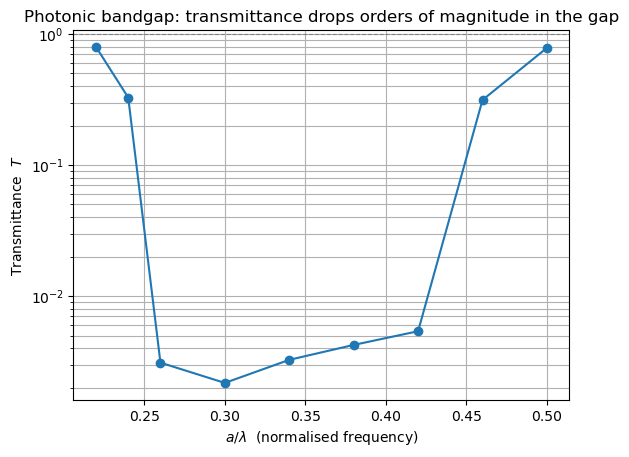

In [2]:
plt.figure()
plt.semilogy(inv_lambda, transmittance, "o-")
plt.axhline(1.0, color="gray", lw=0.8, ls="--")
plt.xlabel(r"$a/\lambda$  (normalised frequency)")
plt.ylabel("Transmittance  $T$")
plt.title("Photonic bandgap: transmittance drops orders of magnitude in the gap")
plt.grid(True, which="both")
plt.savefig(f"{OUTPUT_DIR}/{NAME}.png", dpi=300, bbox_inches="tight")
plt.show()

### Plot 2: field maps, in-gap (reflected) vs out-of-gap (transmitted)


Field maps: in-gap λ = 1.176 μm (reflected), out-of-gap λ = 1.818 μm (transmitted)


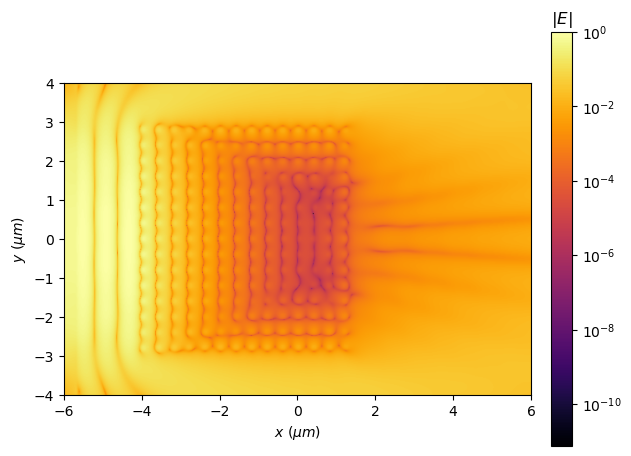

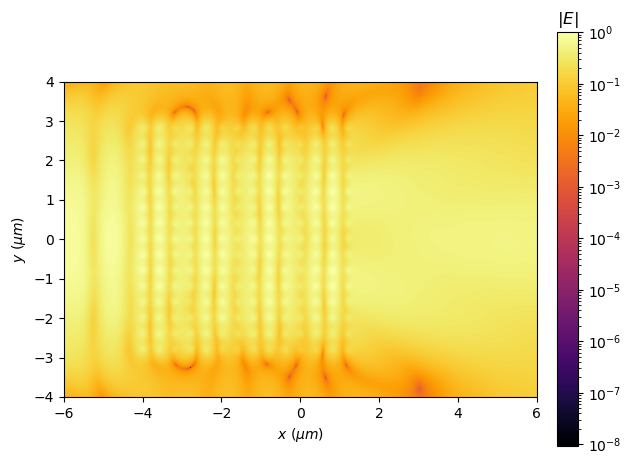

In [3]:
in_gap = min(wavelengths, key=lambda wl: abs(lattice_constant / wl - 0.36))  # ~mid-gap
out_gap = min(wavelengths, key=lambda wl: lattice_constant / wl)  # lowest a/λ -> below gap
print(f"\nField maps: in-gap λ = {in_gap:.3f} μm (reflected), out-of-gap λ = {out_gap:.3f} μm (transmitted)")
plot_computed(fields[in_gap], pixel_size, log=True, save=True, filename=f"{OUTPUT_DIR}/{NAME}_field_in_gap")
plot_computed(fields[out_gap], pixel_size, log=True, save=True, filename=f"{OUTPUT_DIR}/{NAME}_field_out_of_gap")